## Import libraries

In [208]:
import pandas as pd
import os, hashlib, random
from PIL import Image, ImageOps, ImageEnhance
import hashlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras import layers, models, Sequential
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import mlflow
import logging
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import subprocess
from tensorflow.keras.optimizers import Adam
import seaborn as sns

## Read and clean data

In [185]:
dataset_path = "dataset"  # Répertoire racine contenant les sous-dossiers de classes


In [100]:
# Ensemble des empreintes de fichiers pour identifier les doublons
hashes = set()

# Parcourt chaque classe du dataset
for class_name in os.listdir(dataset_path):
    class_dir = os.path.join(dataset_path, class_name)

    # Ignore les éléments qui ne sont pas des dossiers de classe
    if not os.path.isdir(class_dir):
        continue

    print(f"--------- Nettoyage de la classe : {class_name} ---------")

    for filename in os.listdir(class_dir):
        file_path = os.path.join(class_dir, filename)
        
        # Vérifie que l'image n'est pas corrompue
        try:
            with Image.open(file_path) as img:
                img.load()  # Test rapide d'ouverture sans charger l'image entière
        except Exception:
            os.remove(file_path)
            print(f"Image corrompue supprimée : {filename}")
            continue
      
        # Détecte les doublons potentiels
        try:
            # Calcule le hash MD5 pour repérer les doublons
            with open(file_path, 'rb') as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            # Détecte les doublons potentiels
            if file_hash in hashes:
                os.remove(file_path)  # Supprime l'image dupliquée
                print(f"Doublon supprimé : {filename}")
            else:
                hashes.add(file_hash)

        except Exception as e:
            print(f"Erreur de traitement : {filename} ({e})")
        
        # Augmentation du dataset
        try:
            with Image.open(file_path) as img:
               
                # Rotation aléatoire
                rotated = img.rotate(random.uniform(-30, 30))
                rotated.save(os.path.join(class_dir, f"aug_rot_{filename}"))

                # Symétrie horizontale
                flipped = ImageOps.mirror(img)
                flipped.save(os.path.join(class_dir, f"aug_flip_{filename}"))

                # Zoom léger via recadrage
                w, h = img.size
                crop_box = (int(w*0.1), int(h*0.1), int(w*0.9), int(h*0.9))
                cropped = img.crop(crop_box).resize((w, h))
                cropped.save(os.path.join(class_dir, f"aug_zoom_{filename}"))

                # Ajout d'un bruit gaussien
                arr = np.array(img)
                noise = np.random.normal(0, 25, arr.shape).astype(np.uint8)
                noisy = Image.fromarray(np.clip(arr + noise, 0, 255).astype(np.uint8))
                noisy.save(os.path.join(class_dir, f"aug_noise_{filename}"))

                # Variation de luminosité
                enhancer = ImageEnhance.Brightness(img)
                brightness_factor = random.uniform(0.6, 1.4)  # Variation de luminosité comprise entre -40 % et +40 %
                brightened = enhancer.enhance(brightness_factor)
                brightened.save(os.path.join(class_dir, f"aug_bright_{filename}"))

                print(f"Images augmentées pour : {filename}")

        except Exception as e:
            print(f"Erreur d’augmentation : {filename} ({e})")
            
           

--------- Nettoyage de la classe : Castor ---------
Images augmentées pour : Beaver-Track.jpg
Images augmentées pour : Beaver-Tracks-(1).jpg
Images augmentées pour : Beaver-Tracks-(5).jpg
Images augmentées pour : Beaver-Tracks-(7).jpg
Images augmentées pour : Beaver-Tracks-(8).jpg
Images augmentées pour : Beaver-Tracks-3 (1).jpg
Doublon supprimé : Beaver-Tracks-3.jpg
Erreur d’augmentation : Beaver-Tracks-3.jpg ([Errno 2] No such file or directory: 'dataset\\Castor\\Beaver-Tracks-3.jpg')
Images augmentées pour : Beaver-Tracks-4(2).jpg
Images augmentées pour : Beaver-Tracks-8 (1).jpg
Images augmentées pour : original (1).jpg
Images augmentées pour : original (1).png
Images augmentées pour : original (2).jpg
Images augmentées pour : original (2).png
Images augmentées pour : original (3).png
Images augmentées pour : original.jpeg
Images augmentées pour : original.jpg
Images augmentées pour : original.png
--------- Nettoyage de la classe : Chat ---------
Images augmentées pour : Housecat-Tr

## Creating the TensorFlow Dataset from Image Files and split data for training and validation

In [186]:
# Hyperparamètres du chargement des images
batch_size = 16  # Taille des lots lors du chargement
seed = 12  # Graine pour rendre la séparation reproductible
img_size = (180, 180)  # Redimensionnement appliqué à chaque image


In [187]:
# Jeu d'entraînement
train_ds = image_dataset_from_directory(
    dataset_path,  # Dossier source contenant les images classées par dossier
    labels='inferred',  # Déduit les labels à partir des noms de sous-dossiers
    label_mode='categorical', 
    batch_size=batch_size,  # Taille du lot définie ci-dessus
    image_size=img_size,
    shuffle=True,  # Mélange pour limiter les biais liés à l'ordre
    validation_split=0.2,
    subset="training",
    seed=seed,
    color_mode="rgb" 
)

Found 1500 files belonging to 13 classes.
Using 1200 files for training.


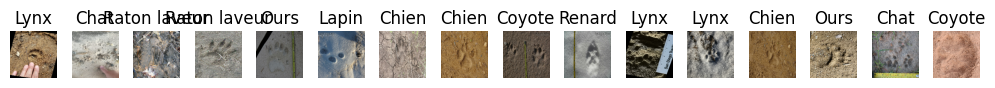

In [188]:
# Aperçu rapide du premier lot d'images
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    num_images = images.shape[0]  # Taille du lot courant
    for i in range(num_images):
        ax = plt.subplot(1, num_images, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"), cmap="gray")
        class_index = labels[i].numpy().argmax()
        plt.title(f"{train_ds.class_names[class_index]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [189]:
# Vérifie les classes détectées par Keras
class_names = train_ds.class_names
print(f"Classes détectées:{len(class_names)} classes:", class_names)

Classes détectées:13 classes: ['Castor', 'Chat', 'Chien', 'Coyote', 'Ecureuil', 'Lapin', 'Loup', 'Lynx', 'Ours', 'Puma', 'Rat', 'Raton laveur', 'Renard']


In [190]:
# Jeu de validation
validation_ds = image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='categorical', 
    batch_size=batch_size,
    image_size=img_size,
    shuffle=True,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    color_mode="rgb"
)

Found 1500 files belonging to 13 classes.
Using 300 files for validation.


## Modeling

In [191]:
# Pipeline d'augmentation appliqué à la volée
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"), 
    layers.RandomRotation(0.1),                   
    layers.RandomZoom(0.1),                       
    layers.RandomTranslation(0.1, 0.1),                     
    layers.RandomBrightness(0.2),                   
    layers.GaussianNoise(0.05), 
])

In [192]:
# Journalisation avec MLflow
logging.getLogger("mlflow").setLevel(logging.ERROR)  # Masque les messages d'information
tf.get_logger().setLevel('ERROR')  # Réduit la verbosité de TensorFlow
mlflow.autolog()
with mlflow.start_run():
    # Définition du modèle CNN
    model = models.Sequential([
        # Pipeline d'augmentation
        data_augmentation,  # Appliqué uniquement pendant l'entraînement

        # Normalisation des pixels
        layers.Rescaling(1./255), 

        # Blocs convolution + pooling
        layers.Conv2D(32, 3, activation='relu'),  # Applique des filtres pour extraire les motifs visuels
        layers.MaxPooling2D(),  # Conserve les motifs dominants et réduit la dimension
      
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
       
        # Passage en dense après aplatissement
        layers.Flatten(),  # Aplati les cartes de caractéristiques en vecteur
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),  # Dropout pour limiter le surapprentissage

        # Couche de sortie
        layers.Dense(len(class_names), activation='softmax')  # Sortie normalisée sur l'ensemble des classes
    ])

In [109]:
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_10 (Sequential)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [193]:
# Compilation du modèle et choix de l'optimiseur
model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss="categorical_crossentropy",
    metrics=['accuracy']
)

In [194]:
# Calcul des poids de classe pour compenser le déséquilibre
y_train = np.concatenate([y.numpy() for x, y in train_ds], axis=0)
y_train = np.argmax(y_train, axis=1) 
class_weights =compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(class_weights))

In [195]:
early_stop = EarlyStopping(
    monitor='val_loss',      
    patience=10,              
    restore_best_weights=True  
)

In [196]:
# Scheduler pour réduire progressivement le taux d'apprentissage
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',     
    factor=0.5,             
    patience=2,           
    verbose=0,               
    min_lr=1e-6             
)

In [197]:
history = model.fit(
    train_ds,  # Données d'entraînement
    validation_data=validation_ds,  # Jeu de validation
    epochs=50,
    callbacks=[reduce_lr, early_stop],
    class_weight=class_weights,
    verbose=1  # Affiche la progression pendant l'entraînement
)

Epoch 1/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 64s 603ms/step - accuracy: 0.0858 - loss: 2.5648 - val_accuracy: 0.0633 - val_loss: 2.5515 - learning_rate: 0.0010
Epoch 2/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 45s 589ms/step - accuracy: 0.0975 - loss: 2.5346 - val_accuracy: 0.1167 - val_loss: 2.4762 - learning_rate: 0.0010
Epoch 3/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.1183 - loss: 2.4868 - val_accuracy: 0.1267 - val_loss: 2.4851 - learning_rate: 0.0010
Epoch 4/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 420ms/step - accuracy: 0.1317 - loss: 2.4508 - val_accuracy: 0.1400 - val_loss: 2.4709 - learning_rate: 0.0010
Epoch 5/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 34s 443ms/step - accuracy: 0.1300 - loss: 2.4589 - val_accuracy: 0.1667 - val_loss: 2.4304 - learning_rate: 0.0010
Epoch 6/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 32s 423ms/step - accuracy: 0.1492 - loss: 2.4074 - val_accuracy: 0.1533 - val_loss: 2.4371 - learning_rate: 0.0010
Epoch 7/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 31s 417ms/step - accuracy: 0.1425 - loss: 2.40

## Learning curves

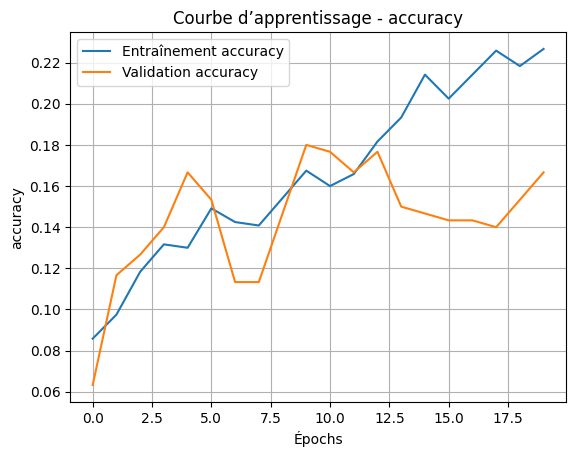

In [198]:
# Courbe d'évolution de l'accuracy
plt.plot(history.history['accuracy'], label='Entraînement accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Courbe d’apprentissage - accuracy')
plt.xlabel('Épochs')
plt.ylabel('accuracy')
plt.legend()
plt.grid(True)
plt.show()

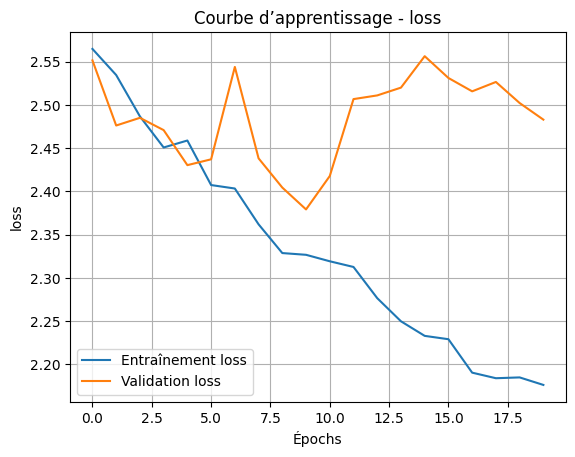

In [199]:
# Courbe d'évolution de la loss
plt.plot(history.history['loss'], label='Entraînement loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Courbe d’apprentissage - loss')
plt.xlabel('Épochs')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

## MLflow

In [116]:
subprocess.Popen(["python", "-m", "mlflow", "ui"])

<Popen: returncode: None args: ['python', '-m', 'mlflow', 'ui']>

## Evaluate model

In [200]:
y_true, y_pred = [], []
for images, labels in validation_ds:
    probs = model.predict(images, verbose=0)
    preds = np.argmax(probs, axis=1)
    true = labels.numpy()
    
    if true.ndim > 1:  # Convertit les labels one-hot en indices de classe
        true = np.argmax(true, axis=1)
            
    y_true.extend(true)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [201]:
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=1)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1       :", f1)

Accuracy : 0.18
Precision: 0.25297090297090297
Recall   : 0.19894340756626805
F1       : 0.146948180236757


In [204]:
labels = list(class_names)

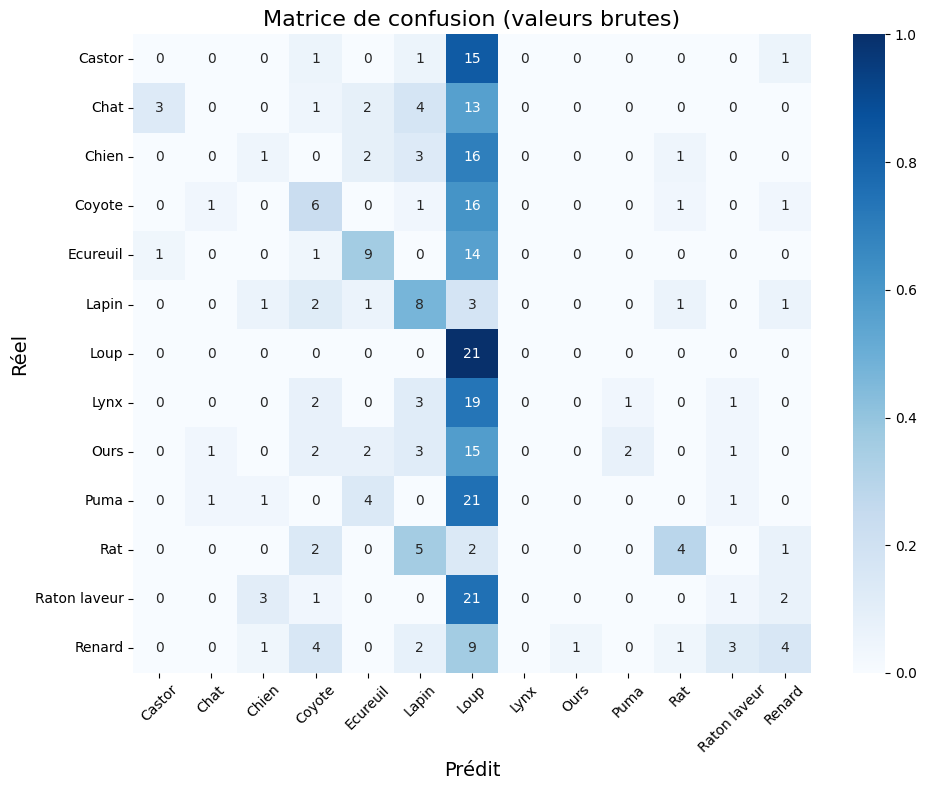

In [209]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=cm, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)

plt.xlabel("Prédit", fontsize=14)
plt.ylabel("Réel", fontsize=14)
plt.title("Matrice de confusion (valeurs brutes)", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [205]:
print(classification_report(
    y_true, y_pred,
    target_names=labels,       
    zero_division=0
))

              precision    recall  f1-score   support

      Castor       0.00      0.00      0.00        18
        Chat       0.00      0.00      0.00        23
       Chien       0.14      0.04      0.07        23
      Coyote       0.27      0.23      0.25        26
    Ecureuil       0.45      0.36      0.40        25
       Lapin       0.27      0.47      0.34        17
        Loup       0.11      1.00      0.20        21
        Lynx       0.00      0.00      0.00        26
        Ours       0.00      0.00      0.00        26
        Puma       0.00      0.00      0.00        28
         Rat       0.50      0.29      0.36        14
Raton laveur       0.14      0.04      0.06        28
      Renard       0.40      0.16      0.23        25

    accuracy                           0.18       300
   macro avg       0.18      0.20      0.15       300
weighted avg       0.17      0.18      0.14       300

